In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.stats import multivariate_normal
from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

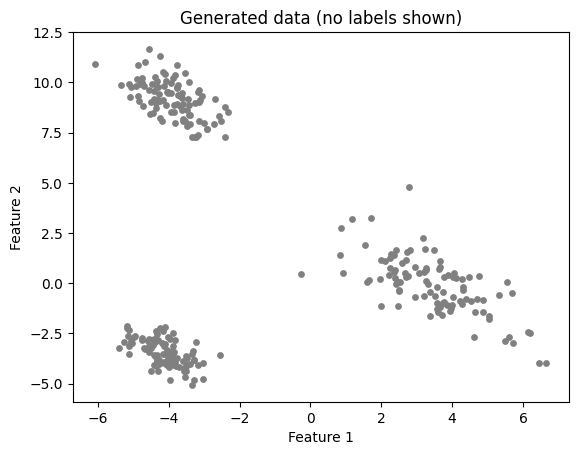

In [2]:
# 300 points from 3 Gaussian clusters
X, true_labels = make_blobs(n_samples=300, centers=3,
                            cluster_std=[1.0, 1.5, 0.7], random_state=42)

# Stretch the data so the clusters become tilted ellipses
X = X @ np.array([[0.8, -0.4], [-0.2, 0.9]])

plt.scatter(X[:, 0], X[:, 1], s=15, color="gray")
plt.title("Generated data (no labels shown)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [3]:
def e_step(X, means, covs, weights):
    """E-step: compute responsibilities (soft cluster memberships)."""
    N, K = X.shape[0], len(weights)
    dens = np.zeros((N, K))
    for k in range(K):
        dens[:, k] = weights[k] * multivariate_normal.pdf(X, mean=means[k], cov=covs[k])
    total = dens.sum(axis=1, keepdims=True)       # sum over clusters for each point
    resp = dens / total                           # each row now sums to 1
    loglik = np.sum(np.log(total))                # how well the model fits the data
    return resp, loglik


def m_step(X, resp):
    """M-step: update weights, means and covariances using the responsibilities."""
    N, D = X.shape
    K = resp.shape[1]
    Nk = resp.sum(axis=0)                         # effective number of points per cluster
    weights = Nk / N
    means = (resp.T @ X) / Nk[:, None]
    covs = np.zeros((K, D, D))
    for k in range(K):
        diff = X - means[k]
        covs[k] = (resp[:, k, None] * diff).T @ diff / Nk[k] + 1e-6 * np.eye(D)
    return means, covs, weights


def em_gmm(X, K, max_iter=100, tol=1e-4, seed=0):
    N, D = X.shape
    rng = np.random.default_rng(seed)

    # Initial guess
    means = X[rng.choice(N, K, replace=False)]           # K random data points
    covs = np.array([np.cov(X.T) for _ in range(K)])     # same covariance for all
    weights = np.ones(K) / K                             # equal mixing weights

    history, loglik_list = [], []
    for it in range(max_iter):
        resp, loglik = e_step(X, means, covs, weights)            # E-step
        history.append((means.copy(), covs.copy(), weights.copy(), resp.copy()))
        loglik_list.append(loglik)
        means, covs, weights = m_step(X, resp)                    # M-step

        if it > 0 and abs(loglik_list[-1] - loglik_list[-2]) < tol:
            break                                                 # converged

    resp, loglik = e_step(X, means, covs, weights)               # final responsibilities
    history.append((means.copy(), covs.copy(), weights.copy(), resp.copy()))
    loglik_list.append(loglik)
    return means, covs, weights, resp, history, loglik_list


K = 3
means, covs, weights, resp, history, loglik_list = em_gmm(X, K)
print("EM stopped after", len(loglik_list) - 1, "iterations")
print("Learned mixing weights:", np.round(weights, 3))
print("Learned means:\n", np.round(means, 2))

EM stopped after 33 iterations
Learned mixing weights: [0.333 0.333 0.333]
Learned means:
 [[-3.92  9.19]
 [-4.12 -3.5 ]
 [ 3.43 -0.09]]


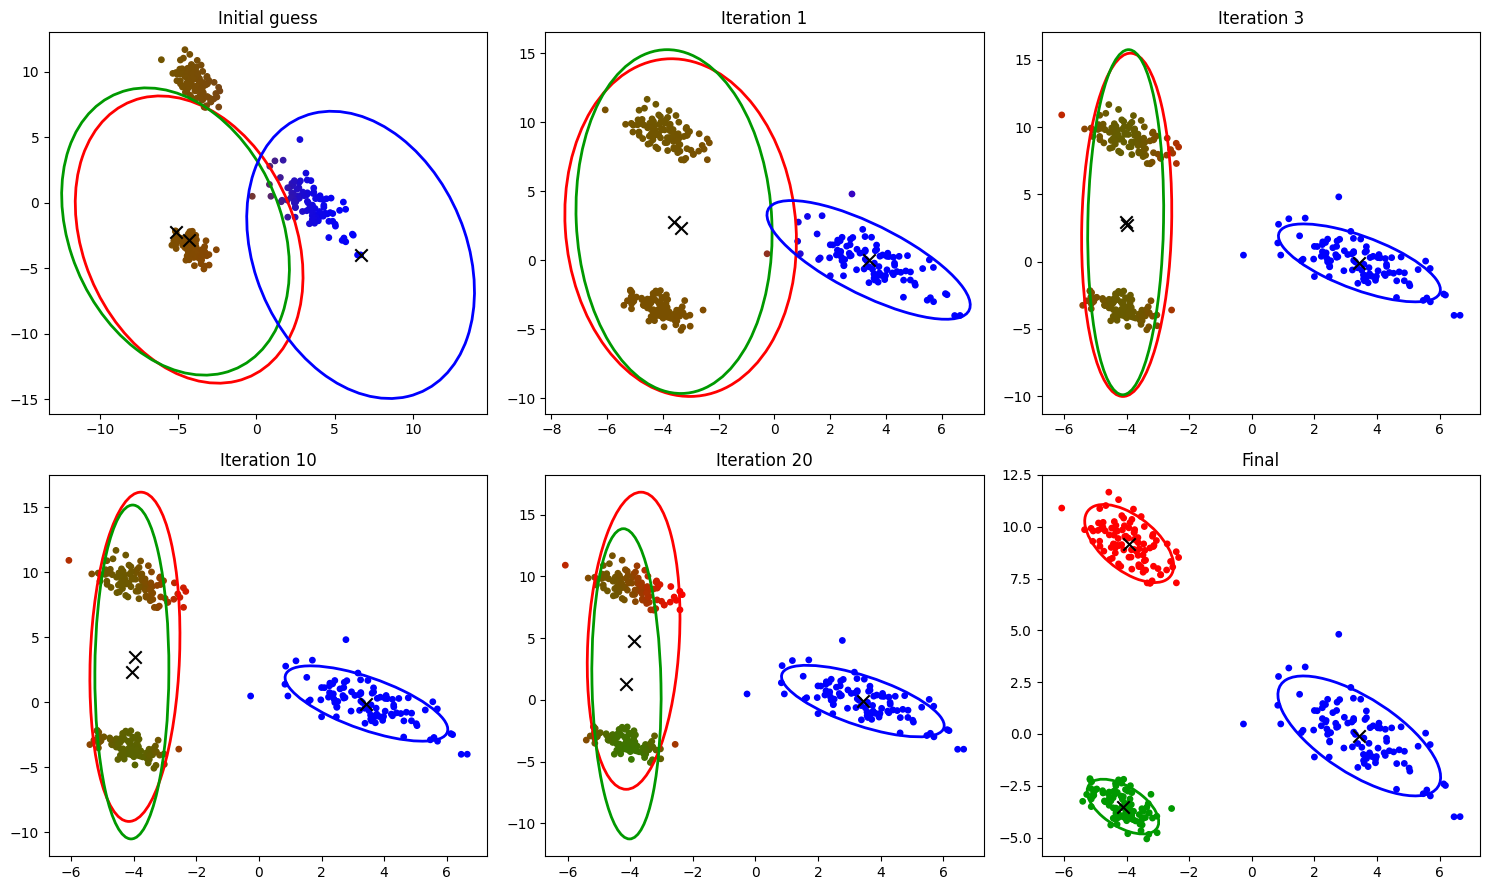

In [4]:
colors = np.array([[1.0, 0.0, 0.0],    # cluster 0 = red
                   [0.0, 0.6, 0.0],    # cluster 1 = green
                   [0.0, 0.0, 1.0]])   # cluster 2 = blue

def draw_ellipse(ax, mean, cov, color, n_std=2):
    vals, vecs = np.linalg.eigh(cov)                       # shape of the cluster
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0])) # tilt angle
    width, height = 2 * n_std * np.sqrt(vals)
    ax.add_patch(Ellipse(mean, width, height, angle=angle,
                         fill=False, edgecolor=color, linewidth=2))

last = len(history) - 1
selected = sorted(set(min(i, last) for i in [0, 1, 3, 10, 20, last]))

cols = 3
rows = int(np.ceil(len(selected) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, 4.5 * rows))
axes = np.array(axes).ravel()

for ax, it in zip(axes, selected):
    m, c, w, r = history[it]
    point_colors = r @ colors                      # blend colors using responsibilities
    ax.scatter(X[:, 0], X[:, 1], c=point_colors, s=15)
    for k in range(K):
        draw_ellipse(ax, m[k], c[k], colors[k])
        ax.scatter(*m[k], marker="x", color="black", s=80)
    name = "Initial guess" if it == 0 else ("Final" if it == last else f"Iteration {it}")
    ax.set_title(name)

for ax in axes[len(selected):]:
    ax.axis("off")                                 # hide unused boxes

plt.tight_layout()
plt.show()

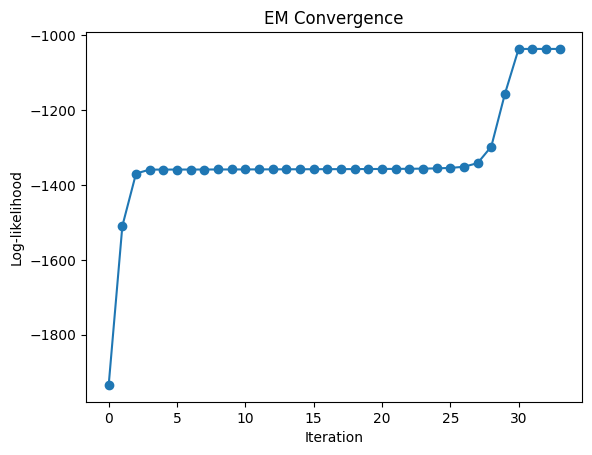

Responsibilities (each row sums to 1):
[[0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]

Most uncertain point: [-2.41  7.29]
Its probabilities   : [1. 0. 0.]


In [5]:
# 1. Log-likelihood vs iteration
plt.plot(loglik_list, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("EM Convergence")
plt.show()

# 2. Soft clustering: probabilities for the first 5 points
print("Responsibilities (each row sums to 1):")
print(np.round(resp[:5], 3))

# 3. The most uncertain point (the one near a cluster boundary)
idx = np.argmin(resp.max(axis=1))
print("\nMost uncertain point:", np.round(X[idx], 2))
print("Its probabilities   :", np.round(resp[idx], 3))

In [6]:
gmm = GaussianMixture(n_components=3, covariance_type="full", random_state=42)
gmm.fit(X)

print("sklearn converged:", gmm.converged_, "in", gmm.n_iter_, "iterations")
print("Weights:", np.round(gmm.weights_, 3))
print("Means:\n", np.round(gmm.means_, 2))

sk_labels = gmm.predict(X)            # hard labels
sk_probs = gmm.predict_proba(X)       # soft probabilities (responsibilities)

sklearn converged: True in 2 iterations
Weights: [0.333 0.333 0.333]
Means:
 [[-3.92  9.19]
 [-4.12 -3.5 ]
 [ 3.43 -0.09]]


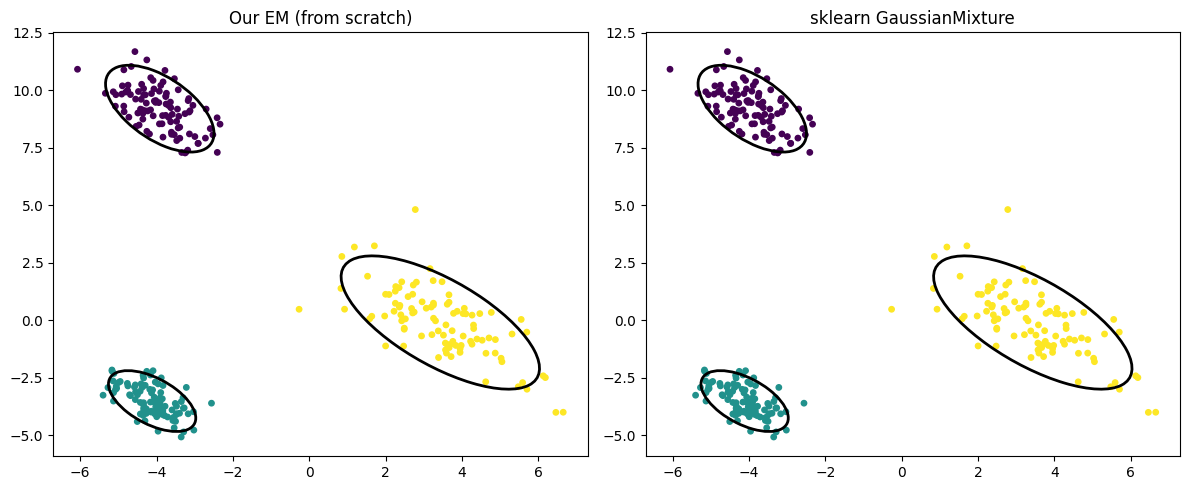

Agreement between our EM and sklearn (ARI): 1.0
Our EM vs true labels      (ARI): 1.0
sklearn vs true labels     (ARI): 1.0
Avg log-likelihood per point -> ours   : -3.4548
Avg log-likelihood per point -> sklearn: -3.4548


In [7]:
our_labels = resp.argmax(axis=1)

# Side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X[:, 0], X[:, 1], c=our_labels, cmap="viridis", s=15)
for k in range(K):
    draw_ellipse(axes[0], means[k], covs[k], "black")
axes[0].set_title("Our EM (from scratch)")

axes[1].scatter(X[:, 0], X[:, 1], c=sk_labels, cmap="viridis", s=15)
for k in range(K):
    draw_ellipse(axes[1], gmm.means_[k], gmm.covariances_[k], "black")
axes[1].set_title("sklearn GaussianMixture")

plt.tight_layout()
plt.show()

# Numeric comparison
print("Agreement between our EM and sklearn (ARI):", round(adjusted_rand_score(our_labels, sk_labels), 4))
print("Our EM vs true labels      (ARI):", round(adjusted_rand_score(true_labels, our_labels), 4))
print("sklearn vs true labels     (ARI):", round(adjusted_rand_score(true_labels, sk_labels), 4))
print("Avg log-likelihood per point -> ours   :", round(loglik_list[-1] / len(X), 4))
print("Avg log-likelihood per point -> sklearn:", round(gmm.score(X), 4))